In [1]:
import pandas as pd
ratings = pd.read_csv("../data/ml-latest-small/ratings.csv")
print(ratings.shape)
ratings.head()

(100836, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [2]:
import pandas as pd

ratings = pd.read_csv("../data/ml-latest-small/ratings.csv")
movies = pd.read_csv("../data/ml-latest-small/movies.csv")
tags = pd.read_csv("../data/ml-latest-small/tags.csv")

print("ratings:", ratings.shape)
print("movies:", movies.shape)
print("tags:", tags.shape)

ratings: (100836, 4)
movies: (9742, 3)
tags: (3683, 4)


In [3]:
print("Missing values:")
print(ratings.isna().sum(), "\n")

print("Duplicate user-movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())
print("Users:", ratings.userId.nunique())
print("Movies rated:", ratings.movieId.nunique())
print("Rating values:", sorted(ratings.rating.unique()))

ratings["date"] = pd.to_datetime(ratings.timestamp, unit="s")
print("Date range:", ratings.date.min(), "to", ratings.date.max())

Missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

Duplicate user-movie pairs: 0
Users: 610
Movies rated: 9724
Rating values: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Date range: 1996-03-29 18:36:55 to 2018-09-24 14:27:30


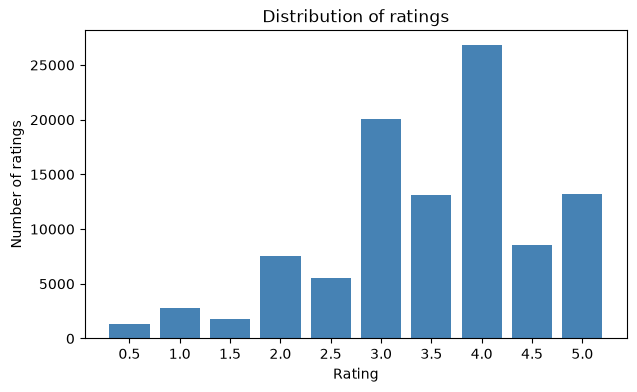

Mean rating: 3.5
Median rating: 3.5
Share of ratings >= 4.0: 0.482

Matrix size: 610 x 9724 = 5,931,640 possible ratings
Actual ratings: 100,836
Density: 1.70%  |  Sparsity: 98.30%


In [4]:
import matplotlib.pyplot as plt

# Rating distribution
counts = ratings.rating.value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(counts.index.astype(str), counts.values, color="steelblue")
plt.title("Distribution of ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

print("Mean rating:", round(ratings.rating.mean(), 2))
print("Median rating:", ratings.rating.median())
print("Share of ratings >= 4.0:", round((ratings.rating >= 4.0).mean(), 3))

# Sparsity of the user-item matrix
n_users = ratings.userId.nunique()
n_items = ratings.movieId.nunique()
density = len(ratings) / (n_users * n_items)
print(f"\nMatrix size: {n_users} x {n_items} = {n_users * n_items:,} possible ratings")
print(f"Actual ratings: {len(ratings):,}")
print(f"Density: {density:.2%}  |  Sparsity: {1 - density:.2%}")

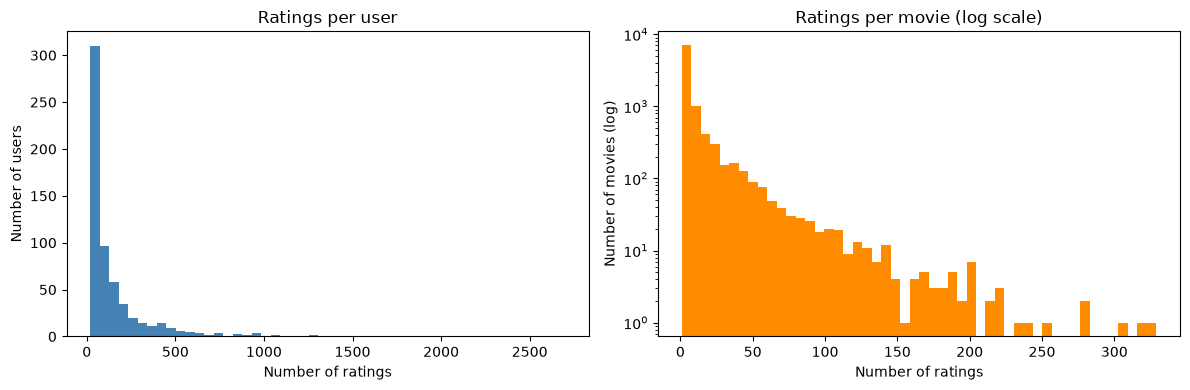

Ratings per user:
count     610.0
mean      165.3
std       269.5
min        20.0
25%        35.0
50%        70.5
75%       168.0
max      2698.0
dtype: float64 

Ratings per movie:
count    9724.0
mean       10.4
std        22.4
min         1.0
25%         1.0
50%         3.0
75%         9.0
max       329.0
dtype: float64 

Movies with only 1 rating: 3446
Movies with fewer than 5 ratings: 6074
Share of all ratings going to the top 100 movies: 0.161


In [5]:
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(per_user, bins=50, color="steelblue")
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Number of users")

axes[1].hist(per_movie, bins=50, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie (log scale)")
axes[1].set_xlabel("Number of ratings")
axes[1].set_ylabel("Number of movies (log)")

plt.tight_layout()
plt.show()

print("Ratings per user:")
print(per_user.describe().round(1), "\n")
print("Ratings per movie:")
print(per_movie.describe().round(1), "\n")
print("Movies with only 1 rating:", (per_movie == 1).sum())
print("Movies with fewer than 5 ratings:", (per_movie < 5).sum())
print("Share of all ratings going to the top 100 movies:",
      round(per_movie.nlargest(100).sum() / len(ratings), 3))

Distinct genres: 20
Movies with no genre listed: 34
Average genres per movie: 2.27


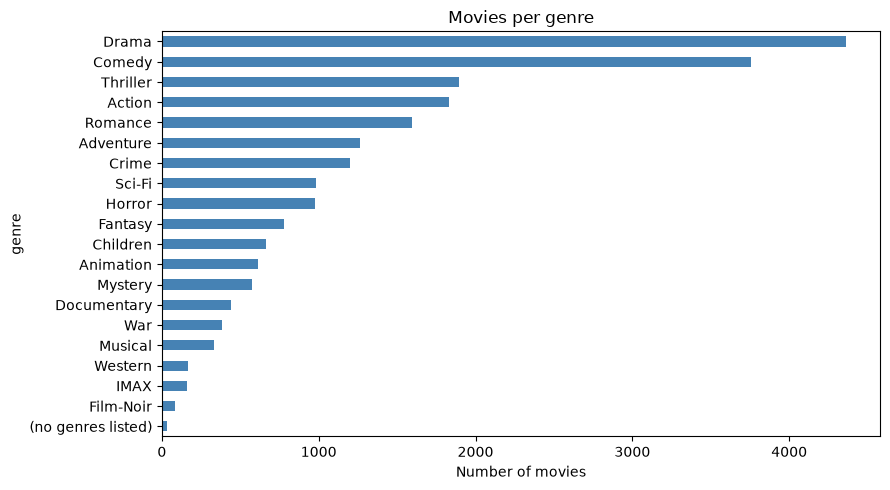

                    n_ratings  avg_rating
genre                                    
Drama                   41928        3.66
Comedy                  39053        3.38
Action                  30635        3.45
Thriller                26452        3.49
Adventure               24161        3.51
Romance                 18124        3.51
Sci-Fi                  17243        3.46
Crime                   16681        3.66
Fantasy                 11834        3.49
Children                 9208        3.41
Mystery                  7674        3.63
Horror                   7291        3.26
Animation                6988        3.63
War                      4859        3.81
IMAX                     4145        3.62
Musical                  4138        3.56
Western                  1930        3.58
Documentary              1219        3.80
Film-Noir                 870        3.92
(no genres listed)         47        3.49


In [6]:
# Each movie has several genres separated by "|"
movies["genre_list"] = movies.genres.str.split("|")
genres = movies.explode("genre_list").rename(columns={"genre_list": "genre"})

genre_counts = genres.genre.value_counts()
print("Distinct genres:", genre_counts.shape[0])
print("Movies with no genre listed:", (movies.genres == "(no genres listed)").sum())
print("Average genres per movie:", round(movies.genre_list.str.len().mean(), 2))

# Number of movies per genre
plt.figure(figsize=(9, 5))
genre_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Movies per genre")
plt.xlabel("Number of movies")
plt.tight_layout()
plt.show()

# Number of ratings and average rating per genre
rated = ratings.merge(genres[["movieId", "genre"]], on="movieId")
genre_stats = rated.groupby("genre").rating.agg(n_ratings="count", avg_rating="mean").round(2)
print(genre_stats.sort_values("n_ratings", ascending=False))

In [7]:
import os
from sklearn.model_selection import train_test_split

cols = ["userId", "movieId", "rating", "timestamp"]
data = ratings[cols].copy()
os.makedirs("../data/splits", exist_ok=True)

# 1) Leave-one-out: latest rating per user is the test item
# (ties in timestamp are broken by movieId so the split is reproducible)
data_sorted = data.sort_values(["userId", "timestamp", "movieId"])
test_loo = data_sorted.groupby("userId").tail(1)
train_loo = data_sorted.drop(test_loo.index)

# 2) 80/20 random split for RMSE (fixed seed so everyone gets the same split)
train_rmse, test_rmse = train_test_split(data, test_size=0.2, random_state=42)

# Save
train_loo.to_csv("../data/splits/train_loo.csv", index=False)
test_loo.to_csv("../data/splits/test_loo.csv", index=False)
train_rmse.to_csv("../data/splits/train_rmse.csv", index=False)
test_rmse.to_csv("../data/splits/test_rmse.csv", index=False)

# Sanity checks
print("LOO train:", train_loo.shape, "| LOO test:", test_loo.shape)
print("Users in LOO test:", test_loo.userId.nunique(), "(expect 610)")
print("Overlap train/test (LOO):",
      len(train_loo.merge(test_loo, on=["userId", "movieId"])), "(expect 0)")
print("Share of LOO test items rated >= 4.0:", round((test_loo.rating >= 4.0).mean(), 3))
print("RMSE train:", train_rmse.shape, "| RMSE test:", test_rmse.shape)
print("RMSE test movies not seen in train:",
      (~test_rmse.movieId.isin(train_rmse.movieId)).sum())

LOO train: (100226, 4) | LOO test: (610, 4)
Users in LOO test: 610 (expect 610)
Overlap train/test (LOO): 0 (expect 0)
Share of LOO test items rated >= 4.0: 0.595
RMSE train: (80668, 4) | RMSE test: (20168, 4)
RMSE test movies not seen in train: 813
